<div style='margin:8px 0 28px; padding:32px 36px; border-radius:20px; color:#ffffff; background:linear-gradient(135deg, #0a6ed1 0%, #073b73 65%, #002a5c 100%); box-shadow:0 14px 34px rgba(7,59,115,.22);'>
<div style='color:#d1e9ff; font-size:.78em; font-weight:800; letter-spacing:.12em;'>AGENT PATTERNS · LESSON 05</div>
<h1 style='margin:10px 0; font-size:2.15em; line-height:1.2; color:#ffffff;'>Build Your Harness</h1>
<p style='margin:0; color:#e8f4ff; line-height:1.65;'>요청을 계획하고, MCP와 Joule Agent를 호출한 뒤, 승인과 trace를 포함한 결과를 전달하는 Harness 구조를 설계합니다.</p>
</div>


<hr style="border:0; border-top:2px solid #c7d2e1; margin:32px 0 14px;">

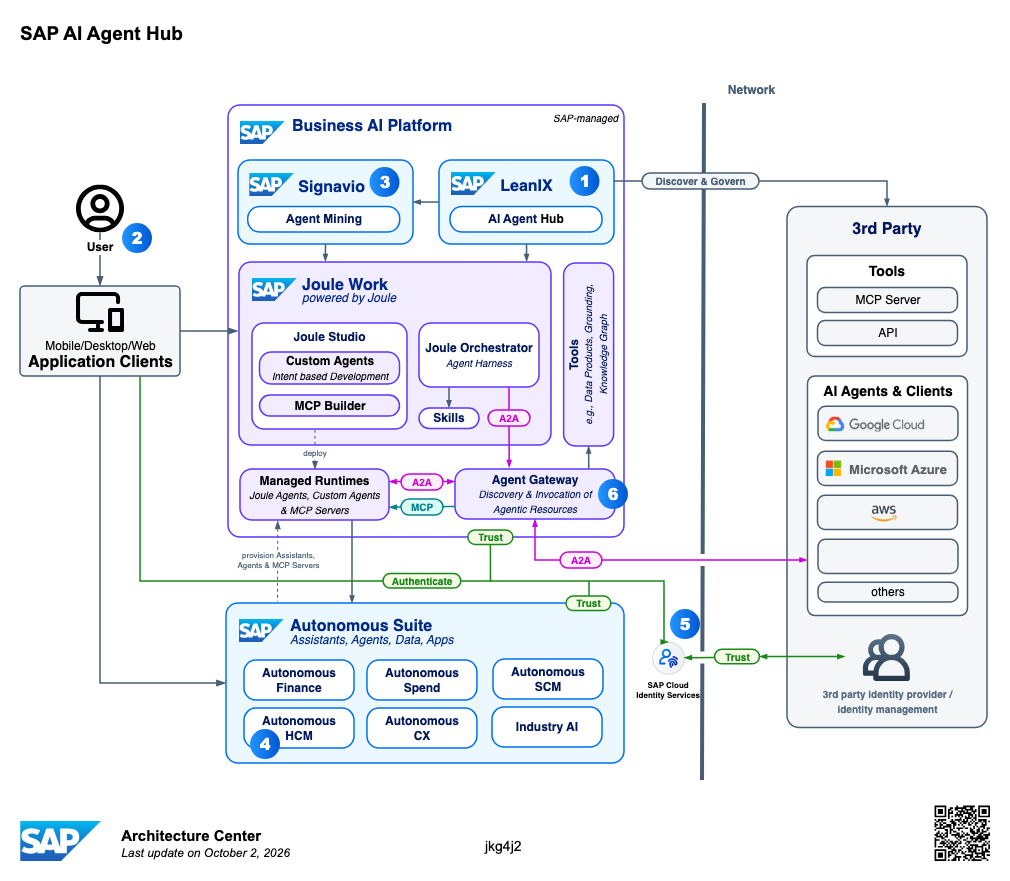

<div style='margin:18px 0 16px; padding:13px 15px; border-left:4px solid #1976d2; background:#eef6ff; border-radius:6px; color:#202124; box-shadow:0 1px 2px rgba(60,64,67,.12);'><div style='font-size:.82em; font-weight:700; color:#1976d2; letter-spacing:.08em;'>02 · IMPLEMENTATION BOUNDARIES</div><h2 style='margin:8px 0; font-size:1.1em; line-height:1.35; color:#0b2f5b;'>SAP 제품별 역할과 구현 경계</h2><p style='margin:0; color:#4b6175; line-height:1.6;'>각 계층의 책임과 구현 전에 확인할 계약을 분리합니다.</p></div>

| 제품 / 계층 | Harness에서 맡기는 일 | 구현 시 확인할 계약 |
| --- | --- | --- |
| SAP AI Core | LLM, reranker, 모델 추론 | 배포 모델, prompt/input schema, token·rate limit |
| SAP Integration Suite | MCP Gateway와 기업 API 연결 | Tool schema, OAuth, 읽기·쓰기 권한, audit |
| Joule Studio / Agents | SAP 업무 Agent를 A2A로 제공 | Agent Card, endpoint, 인증, task·artifact schema |
| SAP HANA Cloud | 상태, memory, checkpoint, trace 저장 | 업무 키, 보존 기간, PII 분류 |
| LeanIX AI Agent Hub | Agent 등록, 검색, 승인, EA 관계 | registry ID, 승인 상태, 동기화 주기 |
| SAP S/4HANA | 구매오더 등 실제 ERP 데이터·트랜잭션 | API scope, 업무 권한, idempotency key |

<hr style="border:0; border-top:2px solid #c7d2e1; margin:32px 0 14px;">

<div style='margin:18px 0 16px; padding:13px 15px; border-left:4px solid #1976d2; background:#eef6ff; border-radius:6px; color:#202124; box-shadow:0 1px 2px rgba(60,64,67,.12);'><div style='font-size:.82em; font-weight:700; color:#1976d2; letter-spacing:.08em;'>04 · AGENT BENCHMARK</div><h2 style='margin:8px 0; font-size:1.1em; line-height:1.35; color:#0b2f5b;'>Agent Benchmark · 핵심 5개 지표</h2><p style='margin:0; color:#4b6175; line-height:1.6;'>같은 task suite에서 후보 Agent와 기준 Agent를 비교합니다.</p></div>

| 지표 | 측정 질문 | 입력·수집 | 판정 방식 | 계산 |
| :--- | :--- | :--- | :--- | :--- |
| **Task Success Rate** | 업무 목표를 실제로 달성했는가? | task ID, 기대 최종 상태, Agent 결과 | DB/API 상태 또는 assertion으로 outcome validator가 pass/fail 판정 | 성공 task / 전체 task |
| **Tool-Use Success Rate** | 필요한 tool을 올바른 인자와 순서로 호출했는가? | tool name, arguments, response, error code trace | schema → 권한/인자 → 응답 성공 여부 검증 | 성공 tool call / 전체 tool call |
| **Safety Violation Rate** | 권한·정책·업무 제약을 위반했는가? | policy, allowlist, 승인 기록, action trace | write-before-approval, scope 초과, PII 노출 탐지 | 위반 action 또는 task / 전체 |
| **Robustness / Consistency** | 입력 변형과 반복 실행에도 안정적인가? | 반복 실행, paraphrase, 누락 정보, tool delay 변형 | baseline 결과와 outcome·핵심 결과 비교 | 성공 run / 전체 run, 변형별 성공률 |
| **Efficiency** | 시간·단계·토큰을 과도하게 쓰지 않았는가? | timestamp, step 수, token usage, 모델·tool 단가 | trace aggregator가 task별 사용량 집계 | p50/p95 latency, 평균 steps/tokens, cost / task |

### 공통 측정 흐름

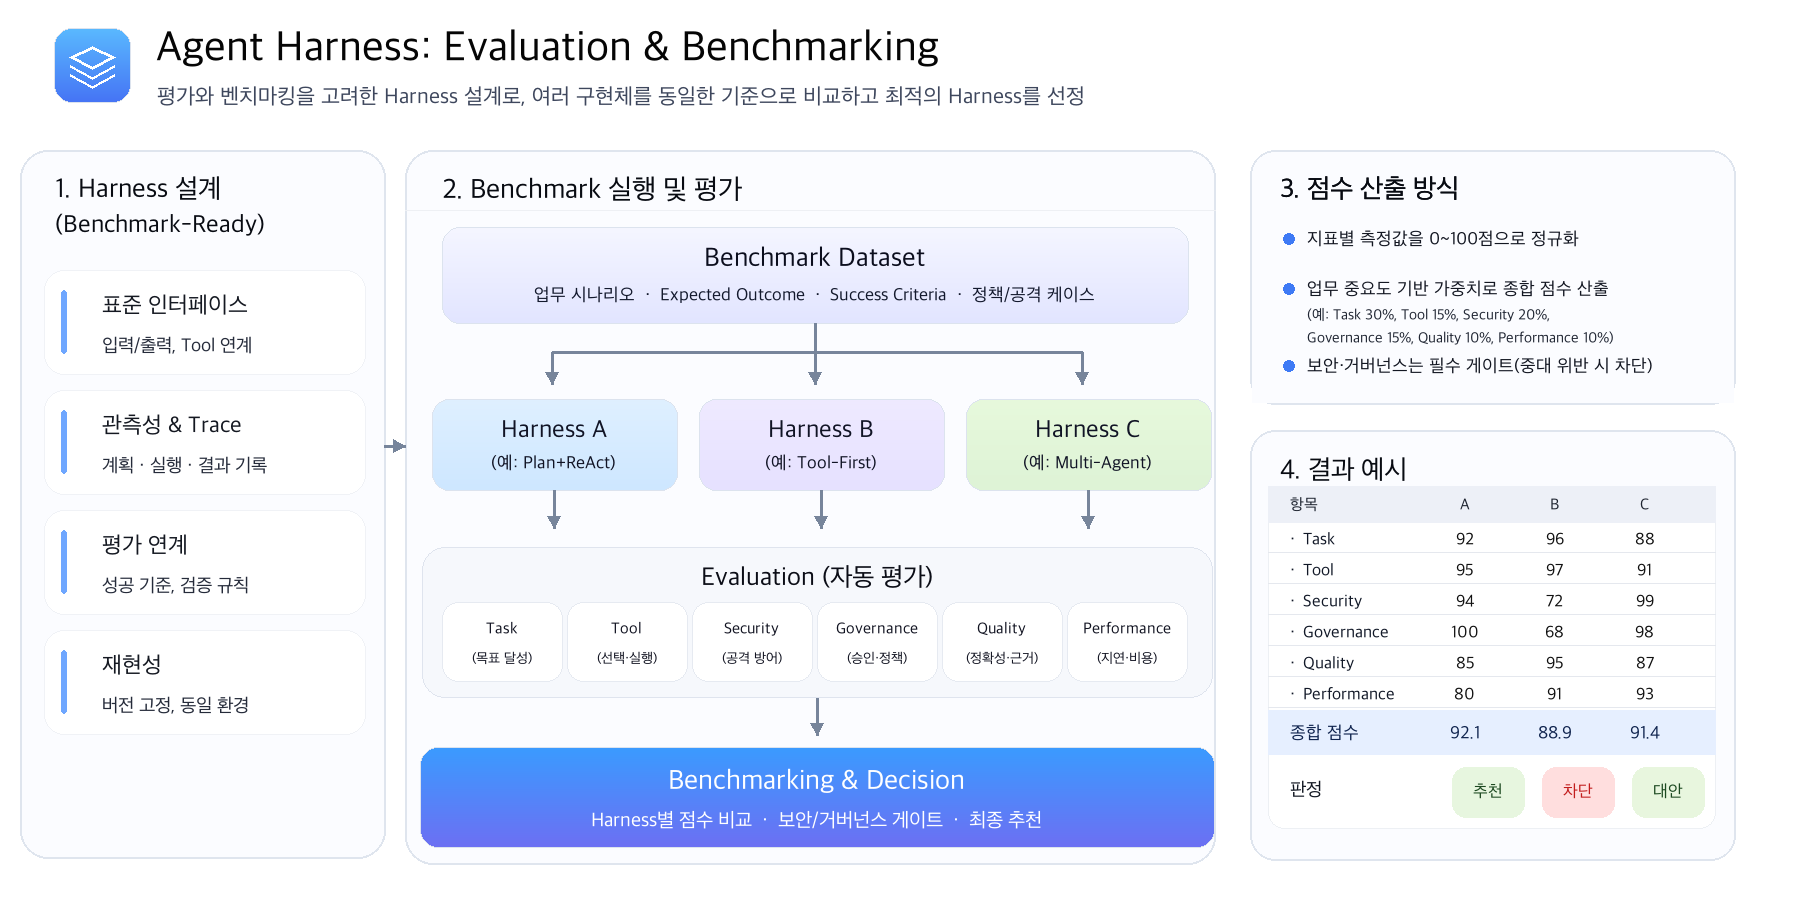


<hr style="border:0; border-top:2px solid #c7d2e1; margin:32px 0 14px;">
<div style='margin:18px 0 16px; padding:13px 15px; border-left:4px solid #1976d2; background:#eef6ff; border-radius:6px; color:#202124; box-shadow:0 1px 2px rgba(60,64,67,.12);'><div style='font-size:.82em; font-weight:700; color:#1976d2; letter-spacing:.08em;'>05 · DEVELOPMENT & OPERATIONS</div><h2 style='margin:8px 0; font-size:1.1em; line-height:1.35; color:#0b2f5b;'>Harness Agent 개발 및 운영 환경</h2><p style='margin:0; color:#4b6175; line-height:1.6;'>Joule·Joule Studio·3rd-party 조합별 개발 유연성, 운영 거버넌스, 비용과 유지보수 부담을 비교합니다.</p></div>

![Harness Agent orchestration and agents ownership matrix](../assets/harness_orchestration_agents_matrix.svg)

![Harness Agent development and operations comparison](../assets/harness_development_operations_5_cases.png)
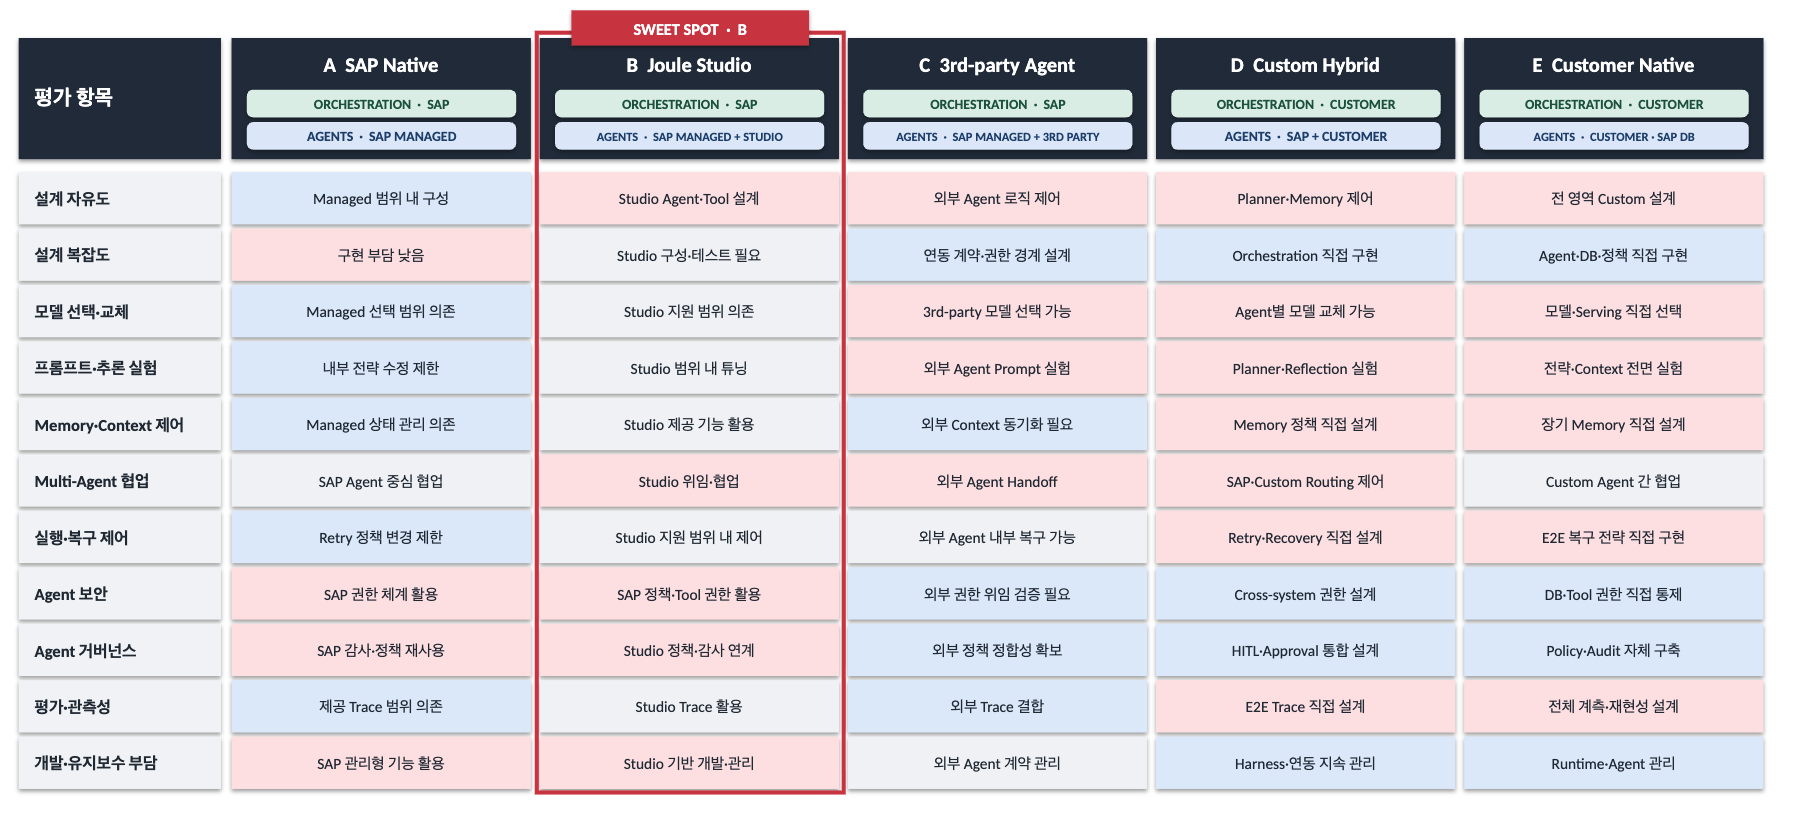

<hr style='border:0; border-top:2px solid #c7d2e1; margin:32px 0 14px;'>
<div style='margin:18px 0 16px; padding:13px 15px; border-left:4px solid #c9203a; background:#fff5f6; border-radius:6px; color:#202124; box-shadow:0 1px 2px rgba(60,64,67,.12);'><div style='font-size:.82em; font-weight:700; color:#c9203a; letter-spacing:.08em;'>06 · SECURITY</div><h2 style='margin:8px 0; font-size:1.1em; line-height:1.35; color:#7b1022;'>AI Agent 생태계의 주요 공격 경로와 위험</h2><p style='margin:0; color:#6b4750; line-height:1.6;'>Harness가 Agent Card, endpoint, 외부 응답, RAG 지식을 신뢰 경계로 검증하지 않으면 비인가 데이터 조회·유출 또는 잘못된 업무 실행으로 이어질 수 있습니다.</p></div>

![AI Agent ecosystem attack paths](../assets/harness_attack_paths.png)



<hr style='border:0; border-top:2px solid #c7d2e1; margin:32px 0 14px;'>
<div style='margin:18px 0 16px; padding:13px 15px; border-left:4px solid #6b3a96; background:#f7f0ff; border-radius:6px; color:#202124; box-shadow:0 1px 2px rgba(60,64,67,.12);'><div style='font-size:.82em; font-weight:700; color:#6b3a96; letter-spacing:.08em;'>07 · GOVERNANCE</div><h2 style='margin:8px 0; font-size:1.1em; line-height:1.35; color:#48206b;'>Harness Agent의 등록부터 폐기까지 통제하는 운영 모델</h2><p style='margin:0; color:#5e4b70; line-height:1.6;'>거버넌스는 실행 경로를 느리게 만드는 승인 절차가 아니라, 어떤 Agent가 어떤 권한과 근거로 업무를 수행하는지 지속적으로 증명하는 운영 체계입니다.</p></div>

![Harness Agent orchestration and agents ownership matrix](../assets/harness_orchestration_agents_matrix.svg)

![Harness Agent governance case comparison](../assets/harness_governance_case_comparison.svg)
